# 03 · Exploratory Data Analysis and Warming Hotspots

Answers research questions **RQ1–RQ3** and motivates the modelling choices for RQ4–RQ5.

| Section | Question |
|---|---|
| 1 | Summary statistics |
| 2 | What do Pakistan's seasonal cycle and geography look like? |
| 3 | How has temperature changed nationally, 2000–2025? (RQ1) |
| 4 | Which districts warmed significantly? Mann-Kendall + Sen's slope + FDR (RQ2) |
| 5 | Does warming depend on season? |
| 6 | Does warming depend on elevation? |
| 7 | Rainfall patterns and the rainfall–temperature relationship (RQ3) |
| 8 | ERA5-Land vs CHIRPS rainfall |
| 9 | Is next month's anomaly predictable? (motivates the ML task) |

All figures are saved to `research/figures/` for the paper and slides.

In [1]:
import sys; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt, seaborn as sns
from src import config as C, preprocessing as P, trends as T, plotting as V
V.set_style()
pd.set_option("display.width", 160)

df = P.load_processed()
gdf = gpd.read_file(C.DATA_RAW / "districts.geojson")[["district_id", "geometry"]]
static = pd.read_csv(C.DATA_RAW / "districts_static.csv")
gdf = gdf.merge(static, on="district_id")
df["dtr_c"] = df["tmax_c"] - df["tmin_c"]          # diurnal temperature range
print(df.shape, "|", df["district_id"].nunique(), "districts |", df["date"].min().date(), "->", df["date"].max().date())

(39312, 34) | 126 districts | 2000-01-01 -> 2025-12-01


## 1. Summary statistics

In [2]:
vars_ = ["tmax_c", "tmin_c", "tmean_c", "dtr_c", "rain_mm", "era5_rain_mm", "soil_moisture", "solar_mj"]
summary = df[vars_].describe(percentiles=[.25, .5, .75]).T
summary["skew"] = df[vars_].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
tmax_c,39312.0,25.51,12.80,-24.63,19.62,28.25,34.89,45.60,-1.30
tmin_c,39312.0,13.53,12.24,-31.39,7.20,15.26,23.40,33.04,-1.06
tmean_c,39312.0,19.62,12.42,-27.83,13.40,22.01,29.30,38.20,-1.19
dtr_c,39312.0,11.99,2.47,4.36,10.30,12.27,13.82,19.02,-0.35
rain_mm,39312.0,36.43,53.30,0.00,2.21,16.20,48.00,609.50,2.83
era5_rain_mm,39312.0,46.63,61.03,0.01,4.05,22.46,66.98,664.55,2.21
soil_moisture,39312.0,0.17,0.11,0.00,0.07,0.15,0.27,0.45,0.34
solar_mj,39312.0,14.67,4.53,1.48,11.74,15.04,18.12,24.12,-0.62


In [3]:
# Same statistics by province (district-month values)
df.groupby("province")[["tmax_c", "tmin_c", "rain_mm", "elevation_m"]].agg(["mean", "std"]).round(1)

tmax_c       tmin_c       rain_mm        elevation_m       
                              mean   std   mean   std    mean    std        mean    std
province                                                                               
Azad Kashmir                  16.8   7.1    5.5   7.5   103.2   77.3      1833.2    0.0
Balochistan                   27.5   8.8   15.0   8.5    18.4   29.7      1053.1  698.6
Gilgit-Baltistan              -3.2  10.9  -12.8   9.9    31.7   29.2      4094.6  441.8
Islamabad Capital Territory   26.5   6.8   14.4   7.4   100.7  108.3       592.0    0.0
Khyber Pakhtunkhwa            21.9  10.7   10.3  10.5    58.7   58.5      1221.2  925.6
Punjab                        30.6   7.2   18.4   7.9    38.7   56.7       220.0  120.1
Sindh                         33.7   6.0   20.9   6.5    19.8   49.2        55.7   45.0

**Reading the table:** rainfall is strongly right-skewed (most district-months are nearly dry, and a few monsoon months are very wet). Its median is far below its mean.
This is why later analyses use rank-based methods (Mann-Kendall, Spearman) for rainfall, and why tree-based models, which don't care about skew, are natural candidates.

## 2. Seasonal cycle and geography

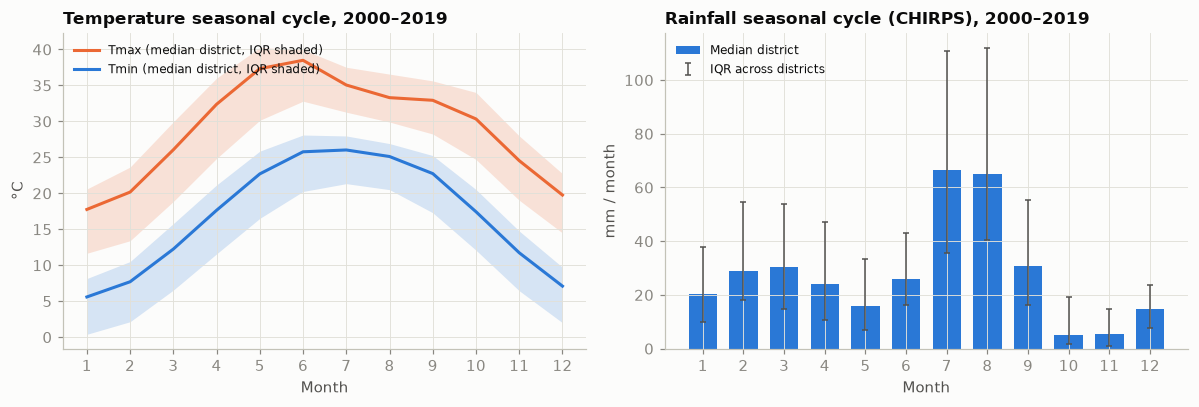

In [4]:
clim = df[df["year"].between(*C.CLIMATOLOGY_YEARS)]
m = clim.groupby(["district_id", "month"])[["tmax_c", "tmin_c", "rain_mm"]].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for var, col, lab in [("tmax_c", V.CATEGORICAL[1], "Tmax"), ("tmin_c", V.CATEGORICAL[0], "Tmin")]:
    q = m.groupby("month")[var].quantile([.25, .5, .75]).unstack()
    ax.fill_between(q.index, q[.25], q[.75], color=col, alpha=.18, linewidth=0)
    ax.plot(q.index, q[.5], color=col, label=f"{lab} (median district, IQR shaded)")
ax.set(title="Temperature seasonal cycle, 2000–2019", xlabel="Month", ylabel="°C", xticks=range(1, 13))
ax.legend(loc="upper left", fontsize=8)
ax = axes[1]
q = m.groupby("month")["rain_mm"].quantile([.25, .5, .75]).unstack()
ax.bar(q.index, q[.5], color=V.CATEGORICAL[0], width=.7, label="Median district")
ax.errorbar(q.index, q[.5], yerr=[q[.5] - q[.25], q[.75] - q[.5]], fmt="none", ecolor=V.INK_2, elinewidth=1, capsize=2, label="IQR across districts")
ax.set(title="Rainfall seasonal cycle (CHIRPS), 2000–2019", xlabel="Month", ylabel="mm / month", xticks=range(1, 13))
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout(); V.save(fig, "eda_01_seasonal_cycle"); plt.show()

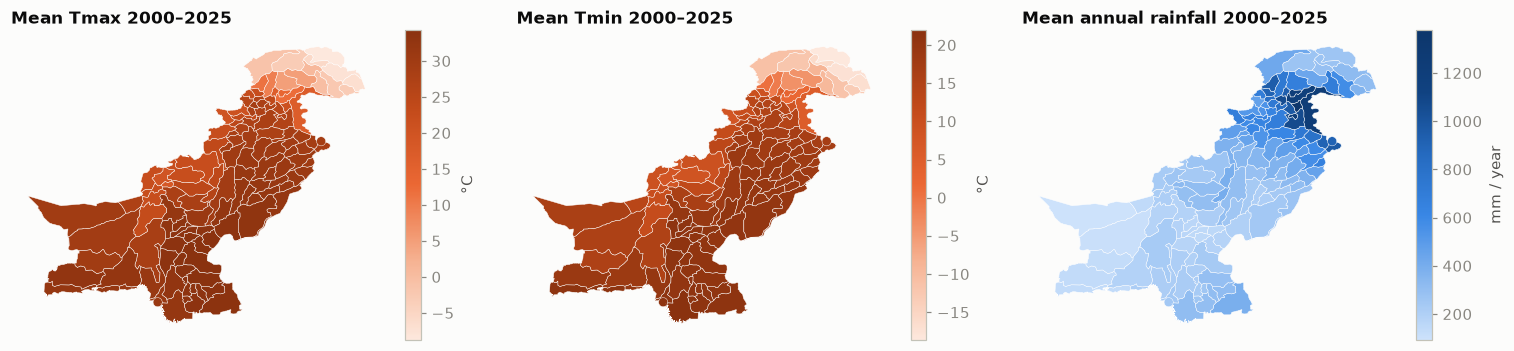

In [5]:
ann = df.groupby("district_id").agg(tmax=("tmax_c", "mean"), tmin=("tmin_c", "mean")).join(
      df.groupby(["district_id", "year"])["rain_mm"].sum().groupby("district_id").mean().rename("rain"))
g = gdf.merge(ann, left_on="district_id", right_index=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, col, cmap, title, lab in [
        (axes[0], "tmax", V.SEQ_ORANGE, "Mean Tmax 2000–2025", "°C"),
        (axes[1], "tmin", V.SEQ_ORANGE, "Mean Tmin 2000–2025", "°C"),
        (axes[2], "rain", V.SEQ_BLUE, "Mean annual rainfall 2000–2025", "mm / year")]:
    g.plot(column=col, cmap=cmap, ax=ax, edgecolor="white", linewidth=.3, legend=True,
           legend_kwds={"shrink": .6, "label": lab})
    ax.set_title(title); V.map_axes(ax)
fig.tight_layout(); V.save(fig, "eda_02_climate_maps"); plt.show()

**Geography dominates the raw values.** The southern plains of Sindh and eastern Balochistan are the hottest. The northern mountains (Gilgit-Baltistan, upper KP) are the coldest. Rainfall is concentrated in the north-east (Punjab, Islamabad, AJK), where the monsoon arrives.
This is why raw temperature is easy to "predict" from location alone, and why our ML target is the **anomaly** (PLAN.md, D1).

## 3. National temperature change, 2000–2025 (RQ1)

The national series is the unweighted mean over the 126 districts. Lines show Sen's slope. Anomalies are relative to 2000–2019.

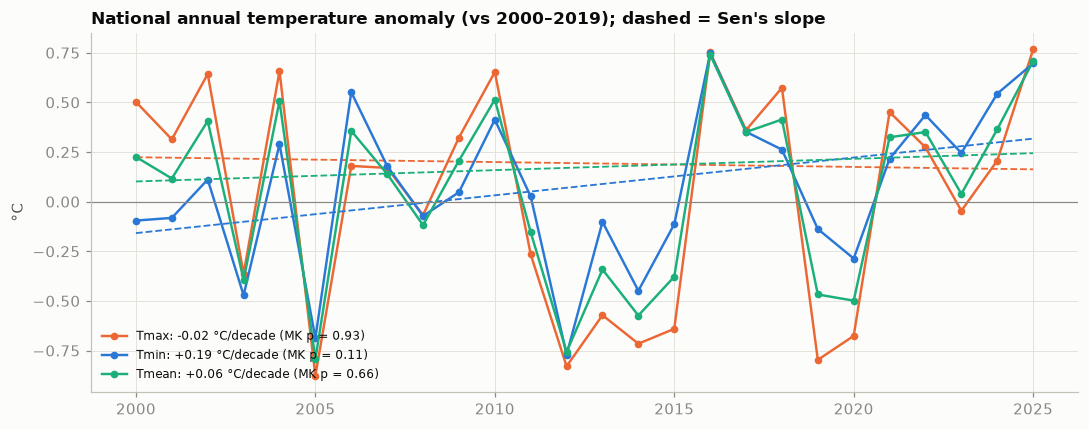

,n_years,tau,p_value,sen_slope_per_decade,sen_intercept
variable,,,,,
Tmax,26,-0.0154,0.9297,-0.0244,0.2238
Tmin,26,0.2246,0.1125,0.1903,-0.1584
Tmean,26,0.0646,0.6593,0.0570,0.1017


In [6]:
nat_rows = []
fig, ax = plt.subplots(figsize=(10, 4))
for var, col, lab in [("tmax_c", V.CATEGORICAL[1], "Tmax"), ("tmin_c", V.CATEGORICAL[0], "Tmin"), ("tmean_c", V.CATEGORICAL[2], "Tmean")]:
    s = df.groupby("year")[var + "_anom"].mean()
    r = T.mk_sen(s.values)
    nat_rows.append({"variable": lab, **r})
    ax.plot(s.index, s.values, color=col, marker="o", markersize=4, linewidth=1.6,
            label=f"{lab}: {r['sen_slope_per_decade']:+.2f} °C/decade (MK p = {r['p_value']:.2f})")
    yrs = s.index.values
    ax.plot(yrs, r["sen_intercept"] + r["sen_slope_per_decade"] / 10 * (yrs - yrs[0]), color=col, linestyle="--", linewidth=1.2)
ax.axhline(0, color=V.MUTED, linewidth=.8)
ax.set(title="National annual temperature anomaly (vs 2000–2019); dashed = Sen's slope", ylabel="°C")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout(); V.save(fig, "eda_03_national_trend"); plt.show()
national = pd.DataFrame(nat_rows).set_index("variable")
national.round(4)

In [7]:
# Hottest and coolest years nationally (Tmax and Tmin anomaly)
yr = df.groupby("year")[["tmax_c_anom", "tmin_c_anom"]].mean().round(2)
pd.concat({"warmest Tmax": yr["tmax_c_anom"].nlargest(5), "warmest Tmin": yr["tmin_c_anom"].nlargest(5)}, axis=1)

,warmest Tmax,warmest Tmin
year,,
2025,0.77,0.70
2016,0.75,0.75
2004,0.66,NaN
2010,0.65,NaN
2002,0.64,NaN
2006,NaN,0.55
2024,NaN,0.54
2022,NaN,0.44


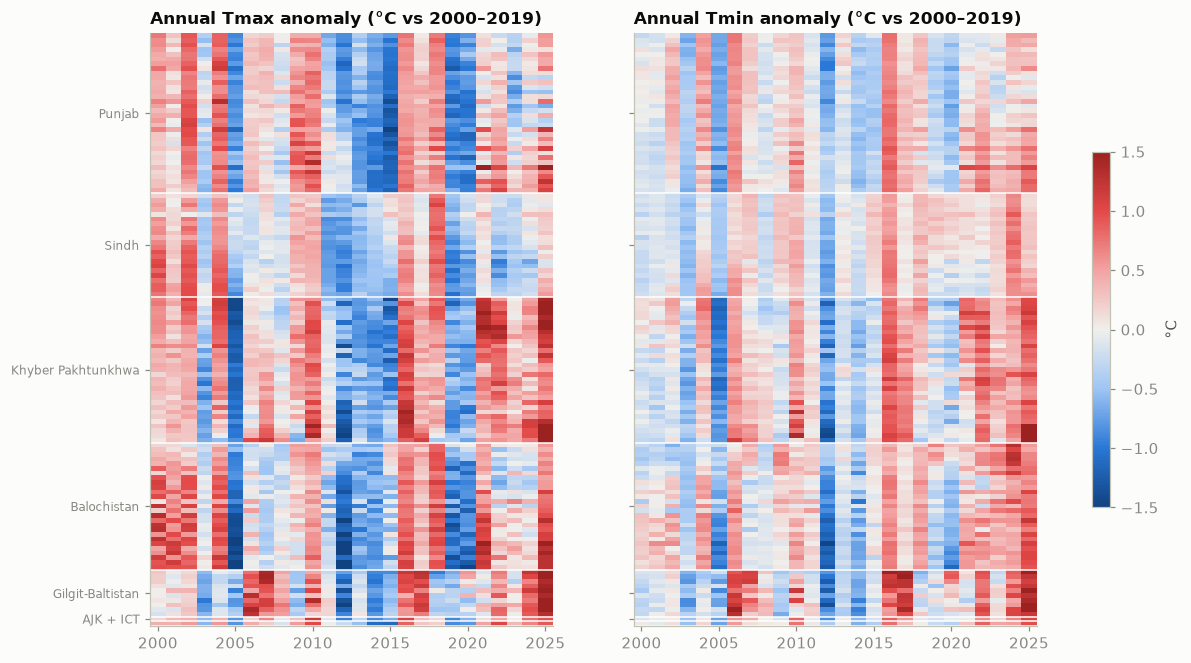

In [8]:
# "Warming stripes" per district: annual Tmin and Tmax anomalies, districts ordered by province then latitude
order = static.assign(p=static["province"].map({p: i for i, p in enumerate(V.PROVINCE_ORDER)})).sort_values(["p", "lat"])
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
for ax, var, title in [(axes[0], "tmax_c_anom", "Annual Tmax anomaly"), (axes[1], "tmin_c_anom", "Annual Tmin anomaly")]:
    h = df.groupby(["district_id", "year"])[var].mean().unstack().loc[order["district_id"]]
    im = ax.imshow(h.values, aspect="auto", cmap=V.DIVERGING, norm=V.symmetric_norm(None, 1.5), interpolation="nearest")
    ax.set_xticks(range(0, h.shape[1], 5)); ax.set_xticklabels(h.columns[::5]); ax.grid(False)
    ax.set_title(f"{title} (°C vs 2000–2019)")
# province labels
bounds = order.reset_index(drop=True).groupby("province", sort=False).apply(lambda x: (x.index.min(), x.index.max()), include_groups=False)
b2 = bounds.drop("Islamabad Capital Territory")
axes[0].set_yticks([(a + b) / 2 for a, b in b2])
axes[0].set_yticklabels(["AJK + ICT" if i == "Azad Kashmir" else i for i in b2.index], fontsize=8)
for a, b in bounds: [ax.axhline(b + .5, color="white", linewidth=1) for ax in axes]
fig.colorbar(im, ax=axes, shrink=.6, label="°C")
V.save(fig, "eda_04_warming_stripes"); plt.show()

## 4. District warming hotspots: Mann-Kendall + Sen's slope (RQ2)

For each district and variable we test the 26 annual means. A district is a **hotspot** only if the Benjamini–Hochberg q-value is below 0.05 **and** Sen's slope is positive (see `src/trends.py`).
We also test the **diurnal temperature range** (DTR = Tmax − Tmin). If nights warm faster than days, DTR shrinks.

In [9]:
results = {}
for var, lab in [("tmax_c", "Tmax"), ("tmin_c", "Tmin"), ("tmean_c", "Tmean"), ("dtr_c", "DTR")]:
    results[lab] = T.district_trends(P.annual_series(df, var))
results["Rain"] = T.district_trends(P.annual_series(df, "rain_mm", how="sum"), up="Significant increase", down="Significant decrease")

counts = pd.DataFrame({k: v["trend_class"].value_counts() for k, v in results.items()}).fillna(0).astype(float)
counts.loc["Median Sen slope / decade"] = [round(v["sen_slope_per_decade"].median(), 3) for v in results.values()]
counts.loc["Districts with positive slope"] = [int((v["sen_slope_per_decade"] > 0).sum()) for v in results.values()]
counts

,Tmax,Tmin,Tmean,DTR,Rain
trend_class,,,,,
No significant trend,122.000,84.000,124.000,63.00,81.000
Significant cooling,0.000,0.000,0.000,44.00,0.000
Significant increase,0.000,0.000,0.000,0.00,3.000
Significant warming,0.000,12.000,0.000,0.00,0.000
p<0.05 but not after FDR,4.000,30.000,2.000,19.00,42.000
Median Sen slope / decade,-0.036,0.196,0.078,-0.21,50.344
Districts with positive slope,56.000,116.000,82.000,1.00,112.000


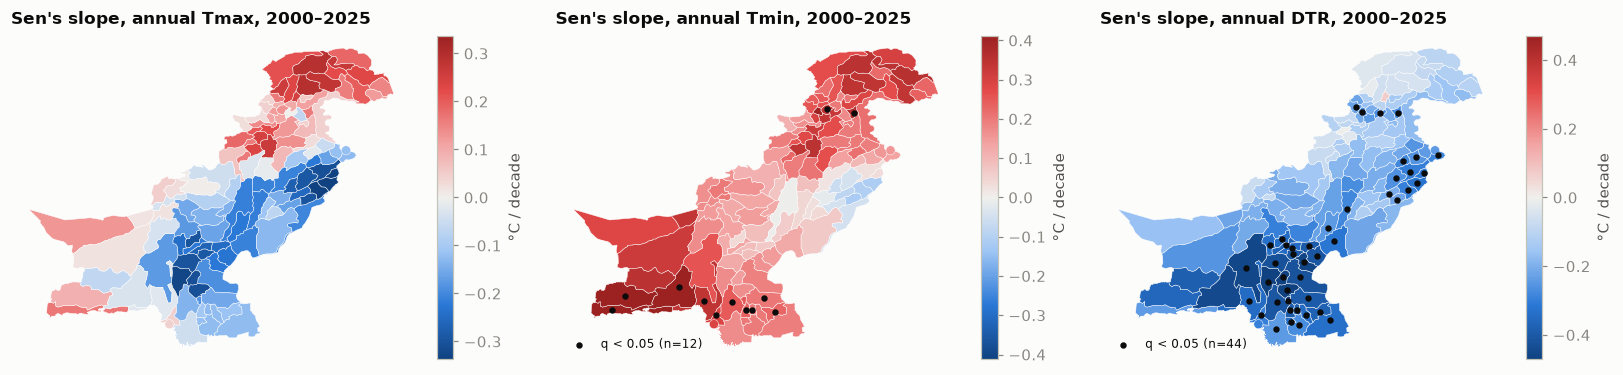

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, lab in zip(axes, ["Tmax", "Tmin", "DTR"]):
    r = gdf.merge(results[lab], left_on="district_id", right_index=True)
    vmax = np.nanpercentile(np.abs(r["sen_slope_per_decade"]), 98)
    r.plot(column="sen_slope_per_decade", cmap=V.DIVERGING, norm=V.symmetric_norm(None, vmax), ax=ax,
           edgecolor="white", linewidth=.3, legend=True, legend_kwds={"shrink": .6, "label": "°C / decade"})
    sig = r[r["q_value"] < T.ALPHA]
    if len(sig):
        ax.scatter(sig.geometry.representative_point().x, sig.geometry.representative_point().y, s=10, color=V.INK, label=f"q < 0.05 (n={len(sig)})")
        ax.legend(loc="lower left", fontsize=8)
    ax.set_title(f"Sen's slope, annual {lab}, 2000–2025"); V.map_axes(ax)
fig.tight_layout(); V.save(fig, "eda_05_trend_maps"); plt.show()

In [11]:
# Top hotspots by Tmin warming (the variable with significant trends), with Tmax and DTR alongside
hot = (results["Tmin"][["sen_slope_per_decade", "p_value", "q_value", "trend_class"]]
       .join(results["Tmax"]["sen_slope_per_decade"].rename("tmax_slope"))
       .join(results["DTR"]["sen_slope_per_decade"].rename("dtr_slope"))
       .join(static.set_index("district_id")[["district", "province", "elevation_m"]]))
hot = hot.sort_values("sen_slope_per_decade", ascending=False)
hot.head(15).round(3)

,sen_slope_per_decade,p_value,q_value,trend_class,tmax_slope,dtr_slope,district,province,elevation_m
district_id,,,,,,,,,
60131773B90188516769392,0.437,0.000,0.008,Significant warming,0.091,-0.363,Kech,Balochistan,428.035
60131773B83658797775488,0.422,0.000,0.009,Significant warming,-0.032,-0.447,Awaran,Balochistan,531.245
60131773B21768890659919,0.416,0.000,0.002,Significant warming,0.167,-0.242,Gwadar,Balochistan,68.974
60131773B23022038026088,0.407,0.011,0.068,p<0.05 but not after FDR,0.123,-0.267,Charsadda,Khyber Pakhtunkhwa,325.974
60131773B72099397094801,0.364,0.003,0.044,Significant warming,0.161,-0.270,Abbottabad,Khyber Pakhtunkhwa,1404.407
60131773B80474055533549,0.356,0.025,0.103,p<0.05 but not after FDR,0.230,-0.119,Shigar,Gilgit-Baltistan,4594.489
60131773B23862504488885,0.353,0.011,0.068,p<0.05 but not after FDR,0.264,-0.172,Mianwali,Punjab,281.146
60131773B61639308877263,0.353,0.043,0.138,p<0.05 but not after FDR,0.269,-0.078,Nagar,Gilgit-Baltistan,4283.771
60131773B78019453337506,0.351,0.006,0.056,p<0.05 but not after FDR,-0.066,-0.385,Panjgur,Balochistan,1008.428


In [12]:
# Hotspots per province
hot.assign(hotspot=hot["trend_class"].eq("Significant warming")).groupby("province").agg(
    districts=("hotspot", "size"), tmin_hotspots=("hotspot", "sum"),
    median_tmin_slope=("sen_slope_per_decade", "median"), median_tmax_slope=("tmax_slope", "median")).round(3)

,districts,tmin_hotspots,median_tmin_slope,median_tmax_slope
province,,,,
Azad Kashmir,1,0,0.214,0.043
Balochistan,27,4,0.167,-0.041
Gilgit-Baltistan,10,0,0.320,0.210
Islamabad Capital Territory,1,0,0.196,0.046
Khyber Pakhtunkhwa,31,2,0.255,0.133
Punjab,34,0,0.066,-0.164
Sindh,22,6,0.189,-0.170


In [13]:
# Save all district trend results for the paper and the dashboard
out = pd.concat({k: v for k, v in results.items()}, axis=1)
out.columns = [f"{a}_{b}" for a, b in out.columns]
out = static.set_index("district_id").join(out)
out.to_csv(C.DATA_PROCESSED / "district_trends.csv")
print("saved", out.shape)

saved (126, 41)


## 5. Seasonal warming

In [14]:
seasonal = {}
for s in P.SEASON_ORDER:
    for var, lab in [("tmax_c", "Tmax"), ("tmin_c", "Tmin")]:
        a = P.annual_series(df, var, season=s)
        r = T.district_trends(a)
        seasonal[(s, lab)] = r
seas_tab = pd.DataFrame({k: {"national slope/dec": T.national_trend(P.annual_series(df, k[1].lower() + "_c", season=k[0]))["sen_slope_per_decade"],
                             "national p": T.national_trend(P.annual_series(df, k[1].lower() + "_c", season=k[0]))["p_value"],
                             "median district slope": v["sen_slope_per_decade"].median(),
                             "q<0.05 warming": (v["trend_class"] == "Significant warming").sum(),
                             "q<0.05 cooling": (v["trend_class"] == "Significant cooling").sum(),
                             "p<0.05 (unadjusted)": (v["p_value"] < .05).sum()} for k, v in seasonal.items()}).T
seas_tab.round(3)

national slope/dec  national p  median district slope  q<0.05 warming  q<0.05 cooling  p<0.05 (unadjusted)
Winter (DJF)      Tmax               0.149       0.559                  0.052             0.0             0.0                  1.0
                  Tmin               0.064       0.870                  0.064             0.0             0.0                  2.0
Pre-monsoon (MAM) Tmax              -0.594       0.146                 -0.671             0.0             0.0                  0.0
                  Tmin              -0.008       1.000                 -0.085             0.0             0.0                  6.0
Monsoon (JJAS)    Tmax               0.116       0.597                  0.145             0.0             0.0                 27.0
                  Tmin               0.340       0.001                  0.325            85.0             0.0                 90.0
Post-monsoon (ON) Tmax              -0.013       0.965                 -0.083             0.0             0.0                  3.0
                  Tmin               0.168       0.567                  0.145             0.0             0.0                  3.0

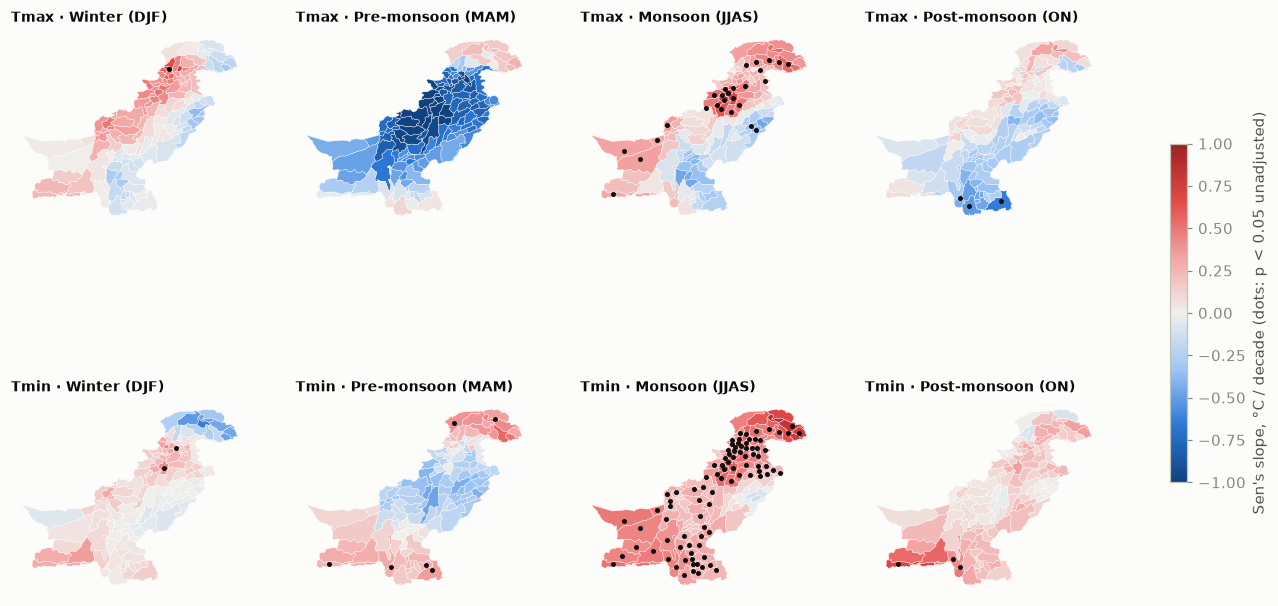

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
vmax = 1.0
for j, s in enumerate(P.SEASON_ORDER):
    for i, lab in enumerate(["Tmax", "Tmin"]):
        ax = axes[i, j]
        r = gdf.merge(seasonal[(s, lab)], left_on="district_id", right_index=True)
        r.plot(column="sen_slope_per_decade", cmap=V.DIVERGING, norm=V.symmetric_norm(None, vmax), ax=ax, edgecolor="white", linewidth=.25)
        sig = r[r["p_value"] < .05]
        ax.scatter(sig.geometry.representative_point().x, sig.geometry.representative_point().y, s=5, color=V.INK)
        ax.set_title(f"{lab} · {s}", fontsize=9); V.map_axes(ax)
sm = plt.cm.ScalarMappable(cmap=V.DIVERGING, norm=V.symmetric_norm(None, vmax))
fig.colorbar(sm, ax=axes, shrink=.5, label="Sen's slope, °C / decade (dots: p < 0.05 unadjusted)")
V.save(fig, "eda_06_seasonal_trend_maps"); plt.show()

## 6. Is warming elevation-dependent?

*Elevation-dependent warming* (EDW) is the hypothesis that mountain regions warm faster than lowlands [Pepin et al., *Nature Climate Change*, 2015]. Pakistan spans 9 m to 4,700 m in district-mean elevation, so this can be tested directly. We use the Spearman rank correlation between elevation and Sen's slope.

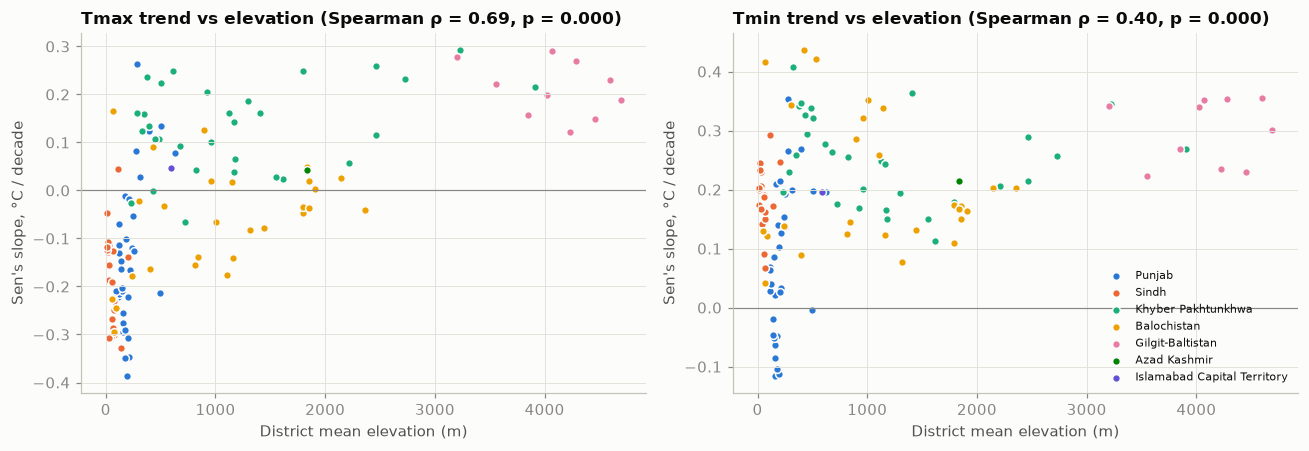

,variable,spearman_rho,p_value
0,Tmax,0.6886,0.0
1,Tmin,0.4021,0.0


In [16]:
from scipy.stats import spearmanr
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
edw = []
for ax, lab in zip(axes, ["Tmax", "Tmin"]):
    r = results[lab].join(static.set_index("district_id")[["elevation_m", "province"]])
    for p in V.PROVINCE_ORDER:
        rp = r[r["province"] == p]
        ax.scatter(rp["elevation_m"], rp["sen_slope_per_decade"], s=26, color=V.PROVINCE_COLORS[p], edgecolor=V.SURFACE, linewidth=1, label=p)
    rho, p = spearmanr(r["elevation_m"], r["sen_slope_per_decade"])
    edw.append({"variable": lab, "spearman_rho": rho, "p_value": p})
    ax.axhline(0, color=V.MUTED, linewidth=.8)
    ax.set(title=f"{lab} trend vs elevation (Spearman ρ = {rho:.2f}, p = {p:.3f})", xlabel="District mean elevation (m)", ylabel="Sen's slope, °C / decade")
axes[1].legend(fontsize=7, loc="best")
fig.tight_layout(); V.save(fig, "eda_07_elevation_dependence"); plt.show()
pd.DataFrame(edw).round(4)

## 7. Rainfall patterns and the rainfall–temperature relationship (RQ3)

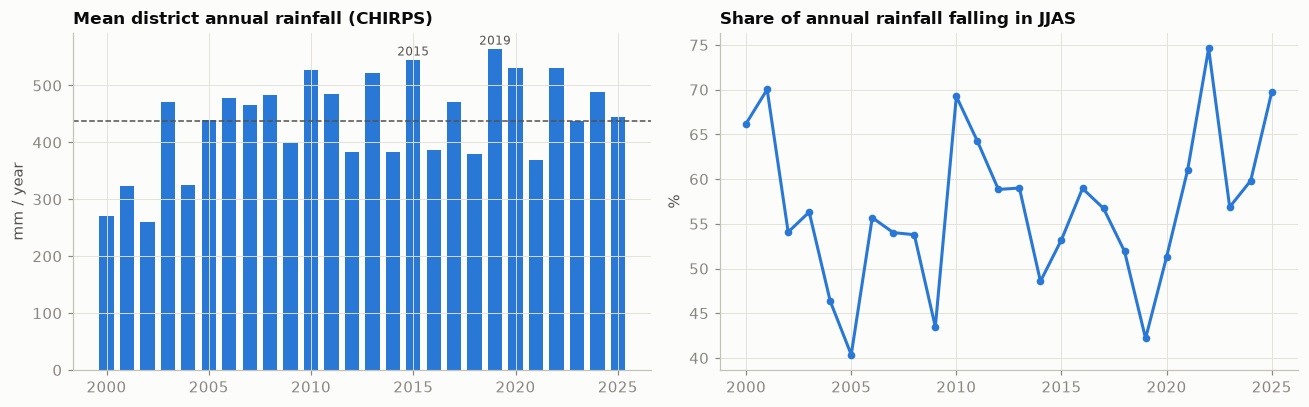

National annual rainfall trend: +49.0 mm/decade, p = 0.043
Wettest years: {2019: 564.0, 2015: 545.0, 2020: 531.0}


In [17]:
annual_rain = df.groupby(["district_id", "year"])["rain_mm"].sum().groupby("year").mean()
monsoon_share = (df[df["season"] == "Monsoon (JJAS)"].groupby("year")["rain_mm"].sum() / df.groupby("year")["rain_mm"].sum())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.bar(annual_rain.index, annual_rain.values, color=V.CATEGORICAL[0], width=.7)
ax.axhline(annual_rain.mean(), color=V.INK_2, linestyle="--", linewidth=1)
for y in annual_rain.nlargest(2).index:
    ax.annotate(str(y), (y, annual_rain[y]), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8, color=V.INK_2)
ax.set(title="Mean district annual rainfall (CHIRPS)", ylabel="mm / year")
ax = axes[1]
ax.plot(monsoon_share.index, monsoon_share.values * 100, color=V.CATEGORICAL[0], marker="o", markersize=4)
ax.set(title="Share of annual rainfall falling in JJAS", ylabel="%")
fig.tight_layout(); V.save(fig, "eda_08_rainfall_annual"); plt.show()
r = T.mk_sen(annual_rain.values)
print(f"National annual rainfall trend: {r['sen_slope_per_decade']:+.1f} mm/decade, p = {r['p_value']:.3f}")
print("Wettest years:", annual_rain.nlargest(3).round(0).to_dict())

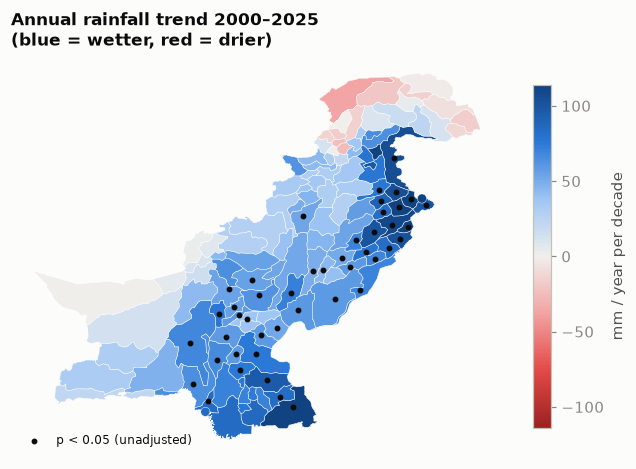

In [18]:
g = gdf.merge(results["Rain"], left_on="district_id", right_index=True)
fig, ax = plt.subplots(figsize=(6, 5.5))
vmax = np.nanpercentile(np.abs(g["sen_slope_per_decade"]), 98)
g.plot(column="sen_slope_per_decade", cmap=V.DIVERGING.reversed(), norm=V.symmetric_norm(None, vmax), ax=ax,
       edgecolor="white", linewidth=.3, legend=True, legend_kwds={"shrink": .6, "label": "mm / year per decade"})
sig = g[g["p_value"] < .05]
ax.scatter(sig.geometry.representative_point().x, sig.geometry.representative_point().y, s=8, color=V.INK, label="p < 0.05 (unadjusted)")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Annual rainfall trend 2000–2025\n(blue = wetter, red = drier)"); V.map_axes(ax)
fig.tight_layout(); V.save(fig, "eda_09_rainfall_trend_map"); plt.show()

**Rainfall vs temperature.** We correlate *anomalies*, not raw values. Raw Tmax and rainfall both peak in summer, so a raw correlation would just reflect the shared seasonal cycle.
Spearman correlation is used because rainfall is skewed. We look at the same month (concurrent) and at the next month (lag 1), the relationship the ML model can exploit.

In [19]:
d = df.sort_values(["district_id", "date"]).copy()
d["tmax_anom_next"] = d.groupby("district_id")["tmax_c_anom"].shift(-1)
rows = []
for s in P.SEASON_ORDER:
    x = d[d["season"] == s]
    rows.append({"season": s,
                 "rain vs Tmax (same month)": spearmanr(x["rain_mm_anom"], x["tmax_c_anom"])[0],
                 "rain vs Tmin (same month)": spearmanr(x["rain_mm_anom"], x["tmin_c_anom"])[0],
                 "soil moisture vs Tmax (same month)": spearmanr(x["soil_moisture_anom"], x["tmax_c_anom"])[0],
                 "rain(t) vs Tmax(t+1)": spearmanr(x["rain_mm_anom"], x["tmax_anom_next"], nan_policy="omit")[0],
                 "soil(t) vs Tmax(t+1)": spearmanr(x["soil_moisture_anom"], x["tmax_anom_next"], nan_policy="omit")[0]})
rt = pd.DataFrame(rows).set_index("season")
rt.round(3)

,rain vs Tmax (same month),rain vs Tmin (same month),soil moisture vs Tmax (same month),rain(t) vs Tmax(t+1),soil(t) vs Tmax(t+1)
season,,,,,
Winter (DJF),-0.309,0.163,-0.539,-0.094,-0.140
Pre-monsoon (MAM),-0.536,-0.261,-0.682,-0.329,-0.344
Monsoon (JJAS),-0.475,-0.067,-0.768,-0.251,-0.206
Post-monsoon (ON),-0.451,-0.024,-0.582,-0.204,-0.255


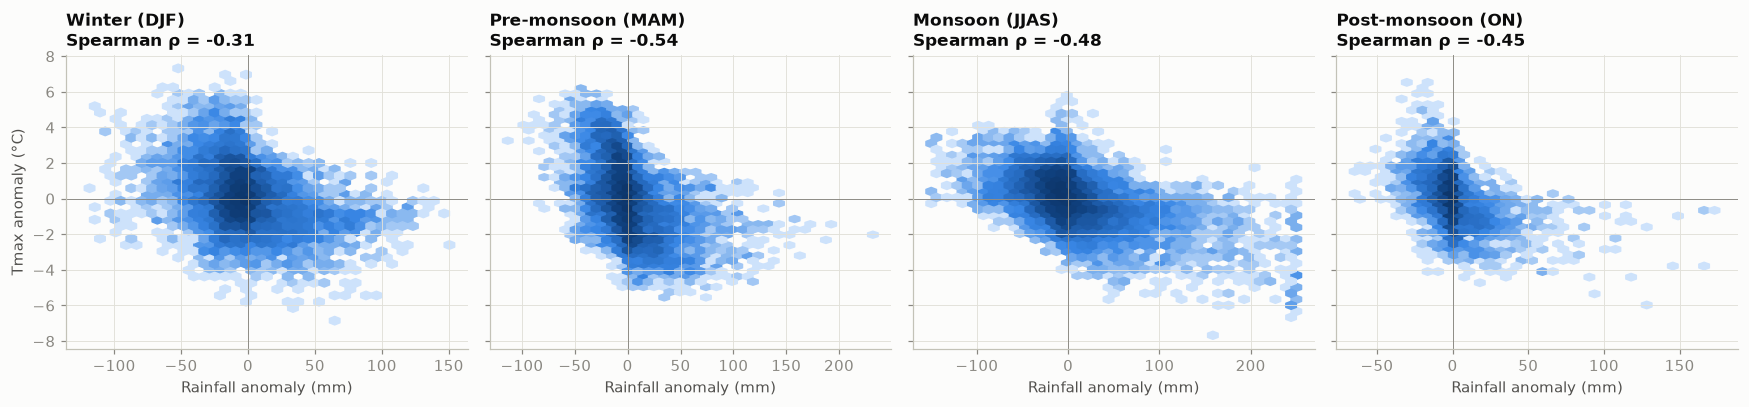

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, s in zip(axes, P.SEASON_ORDER):
    x = d[d["season"] == s]
    ax.hexbin(x["rain_mm_anom"].clip(-150, 250), x["tmax_c_anom"], gridsize=35, cmap=V.SEQ_BLUE, mincnt=1, bins="log")
    ax.axhline(0, color=V.MUTED, linewidth=.6); ax.axvline(0, color=V.MUTED, linewidth=.6)
    ax.set(title=f"{s}\nSpearman ρ = {rt.loc[s, 'rain vs Tmax (same month)']:.2f}", xlabel="Rainfall anomaly (mm)")
axes[0].set_ylabel("Tmax anomaly (°C)")
fig.tight_layout(); V.save(fig, "eda_10_rain_vs_tmax"); plt.show()

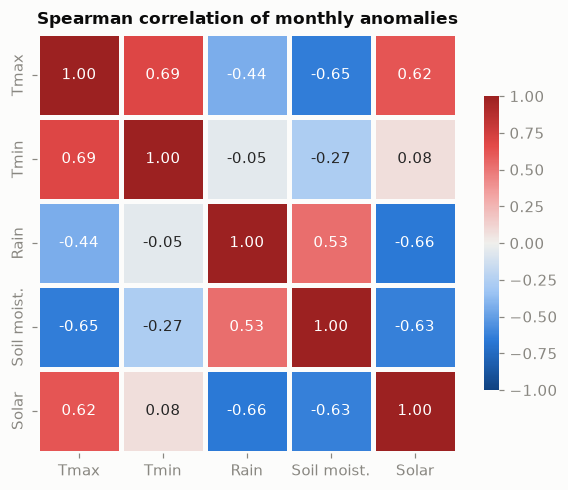

In [21]:
anom_cols = ["tmax_c_anom", "tmin_c_anom", "rain_mm_anom", "soil_moisture_anom", "solar_mj_anom"]
corr = df[anom_cols].corr(method="spearman")
corr.index = corr.columns = ["Tmax", "Tmin", "Rain", "Soil moist.", "Solar"]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=V.DIVERGING, vmin=-1, vmax=1, square=True, linewidths=2, linecolor=V.SURFACE, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Spearman correlation of monthly anomalies"); ax.grid(False)
fig.tight_layout(); V.save(fig, "eda_11_anomaly_correlation"); plt.show()

## 8. ERA5-Land vs CHIRPS rainfall

We use two rainfall products, so we check how far they agree. CHIRPS blends satellite estimates with rain-gauge observations. ERA5-Land precipitation is model-based.

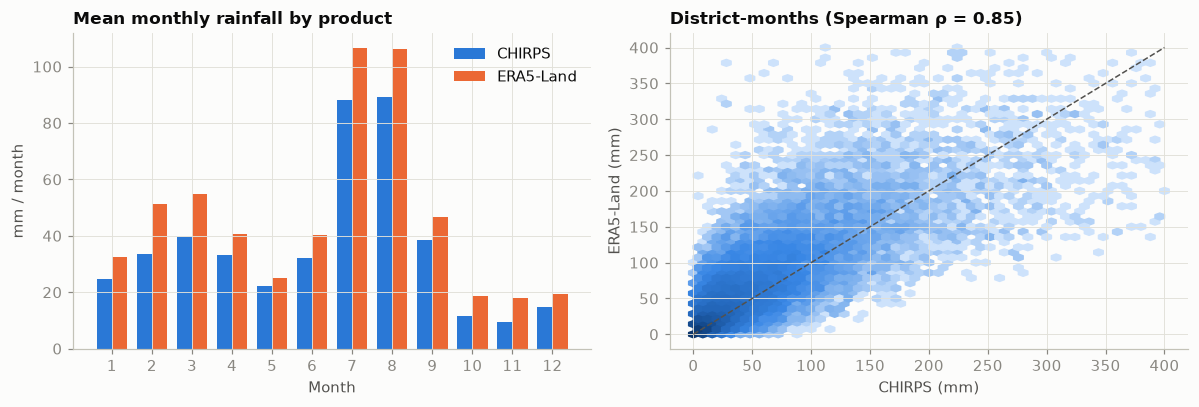

Mean bias ERA5 - CHIRPS: +10.2 mm/month (+28% of CHIRPS mean); ERA5 higher in 63% of district-months


In [22]:
mm = df.groupby("month")[["rain_mm", "era5_rain_mm"]].mean()
bias = (df["era5_rain_mm"] - df["rain_mm"])
r_sp = spearmanr(df["rain_mm"], df["era5_rain_mm"])[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
w = .38
ax.bar(mm.index - w / 2, mm["rain_mm"], width=w, color=V.CATEGORICAL[0], label="CHIRPS")
ax.bar(mm.index + w / 2, mm["era5_rain_mm"], width=w, color=V.CATEGORICAL[1], label="ERA5-Land")
ax.set(title="Mean monthly rainfall by product", xlabel="Month", ylabel="mm / month", xticks=range(1, 13)); ax.legend()
ax = axes[1]
ax.hexbin(df["rain_mm"], df["era5_rain_mm"], gridsize=50, cmap=V.SEQ_BLUE, bins="log", mincnt=1, extent=(0, 400, 0, 400))
ax.plot([0, 400], [0, 400], color=V.INK_2, linestyle="--", linewidth=1)
ax.set(title=f"District-months (Spearman ρ = {r_sp:.2f})", xlabel="CHIRPS (mm)", ylabel="ERA5-Land (mm)")
fig.tight_layout(); V.save(fig, "eda_12_chirps_vs_era5"); plt.show()
print(f"Mean bias ERA5 - CHIRPS: {bias.mean():+.1f} mm/month ({bias.mean() / df['rain_mm'].mean() * 100:+.0f}% of CHIRPS mean); "
      f"ERA5 higher in {(bias > 0).mean() * 100:.0f}% of district-months")

## 9. Is next month's anomaly predictable? (motivates RQ4–RQ5)

If this month's anomaly says nothing about next month's, no model can beat the *climatology* baseline (predicting 0).
The **lag autocorrelation** of Tmax anomalies, computed on training years only, tells us how much "memory" there is to exploit.

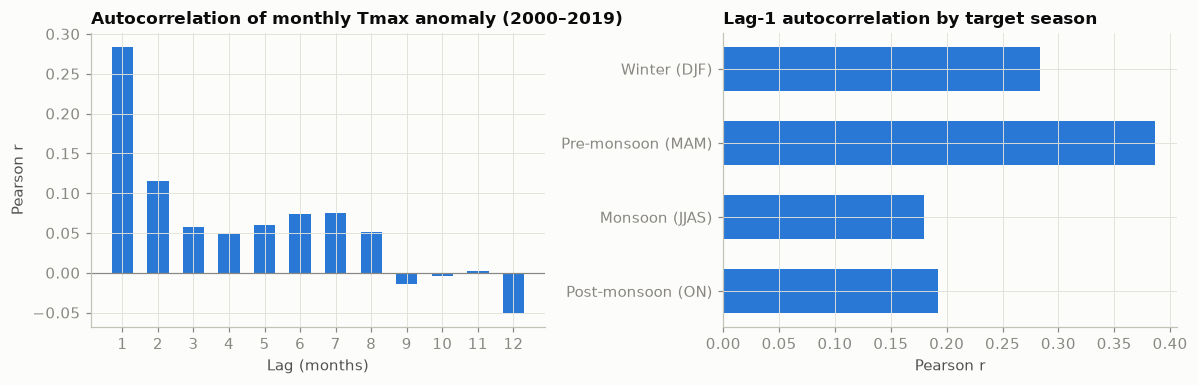

lag-1 r = 0.284 | by season: {'Winter (DJF)': np.float64(0.284), 'Pre-monsoon (MAM)': np.float64(0.387), 'Monsoon (JJAS)': np.float64(0.18), 'Post-monsoon (ON)': np.float64(0.192)}


In [23]:
train = df[df["year"] <= C.TRAIN_YEARS[1]].sort_values(["district_id", "date"])
acf = {}
for lag in range(1, 13):
    sh = train.groupby("district_id")["tmax_c_anom"].shift(lag)
    acf[lag] = train["tmax_c_anom"].corr(sh)
by_season = {}
sh1 = train.groupby("district_id")["tmax_c_anom"].shift(1)
for s in P.SEASON_ORDER:
    msk = train["season"] == s     # season of the month being predicted
    by_season[s] = train.loc[msk, "tmax_c_anom"].corr(sh1[msk])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(list(acf), list(acf.values()), color=V.CATEGORICAL[0], width=.6)
axes[0].axhline(0, color=V.MUTED, linewidth=.8)
axes[0].set(title="Autocorrelation of monthly Tmax anomaly (2000–2019)", xlabel="Lag (months)", ylabel="Pearson r", xticks=range(1, 13))
axes[1].barh(list(by_season)[::-1], list(by_season.values())[::-1], color=V.CATEGORICAL[0], height=.6)
axes[1].set(title="Lag-1 autocorrelation by target season", xlabel="Pearson r")
fig.tight_layout(); V.save(fig, "eda_13_anomaly_persistence"); plt.show()
print("lag-1 r =", round(acf[1], 3), "| by season:", {k: round(v, 3) for k, v in by_season.items()})

In [24]:
# Extreme-heat threshold for the secondary classification task (PLAN.md, D3): 90th percentile of training anomalies
thr = np.percentile(train["tmax_c_anom"], C.EXTREME_HEAT_PERCENTILE)
rate = df.assign(extreme=df["tmax_c_anom"] > thr).groupby(np.select(
    [df["year"] <= C.TRAIN_YEARS[1], df["year"] <= C.VAL_YEARS[1]], ["train", "validation"], "test"))["extreme"].mean()
print(f"Extreme-heat threshold: Tmax anomaly > {thr:.2f} °C")
(rate * 100).round(1).rename("% of district-months extreme").loc[["train", "validation", "test"]]

Extreme-heat threshold: Tmax anomaly > 1.79 °C


train         10.0
validation    13.8
test          17.8
Name: % of district-months extreme, dtype: float64

## 10. Summary of EDA findings

All numbers come from the cells above (ERA5-Land / CHIRPS, 126 districts, 2000–2025).

**F1. Nights warm, days do not (RQ1).** Nationally, annual Tmin rose by **+0.19 °C/decade**, while Tmax shows essentially **no trend (−0.02 °C/decade, MK p = 0.93)**. 116 of 126 districts have a positive Tmin slope, against 56 for Tmax. As a result, the **diurnal temperature range shrank** in 125 of 126 districts, and significantly (FDR q < 0.05) in 44 of them. 2025 and 2016 were the warmest years for both Tmax and Tmin.

**F2. Hotspots depend on the variable (RQ2).** No district has a significant Tmax trend after FDR correction. **12 districts are significant Tmin warming hotspots**, concentrated in coastal and southern Balochistan (Kech, Awaran, Gwadar) and Sindh (6 districts), plus 2 in KP (e.g. Abbottabad). Without the FDR correction, 42 districts would have been called significant. This shows why the correction matters.

**F3. Warming is seasonal: the monsoon season stands out.** Monsoon-season (JJAS) Tmin warmed by +0.34 °C/decade nationally (p = 0.001), with **85 districts significant after FDR**, by far the strongest signal in the dataset. Pre-monsoon (MAM) Tmax shows a broad, non-significant *cooling* (−0.59 °C/decade nationally, p = 0.15) across the plains.

**F4. Warming is elevation-dependent.** District Tmax trends rise with elevation (Spearman ρ = 0.69, p < 0.001). The mountain north (Gilgit-Baltistan, upper KP) warms at about +0.15 to +0.30 °C/decade, while the low plains of Punjab and Sindh show Tmax *cooling* of up to −0.4 °C/decade. This agrees with the elevation-dependent warming hypothesis (Pepin et al., 2015).
*Possible explanation, not tested here:* the plains of Punjab and Sindh are among the most intensively irrigated land on Earth. Irrigation cools daytime temperatures through evaporation and adds humidity, which keeps nights warm. This fits both F1 and F4. It is a hypothesis for the Discussion section, to support with literature, not a result of this study.

**F5. Rainfall (RQ3).** Mean district rainfall increased by +49 mm/decade (MK p = 0.043), with the wettest years in 2019, 2015 and 2020. Only 3 districts are significant after FDR. In every season, wetter-than-normal months are cooler by day: Spearman ρ between rainfall and Tmax anomaly is −0.31 to −0.54, and soil moisture is even stronger at −0.54 to −0.77. Rain has little effect on Tmin.

**F6. Data-source uncertainty.** ERA5-Land rainfall is on average +10.2 mm/month (+28%) higher than CHIRPS. We therefore use CHIRPS (gauge-corrected) as the primary rainfall variable and report this as a limitation.

**F7. Implications for the ML task (RQ4–RQ5).**
* Tmax anomalies have only modest month-to-month memory: lag-1 r = 0.28 overall, 0.39 when predicting pre-monsoon months, 0.18 for monsoon months. Persistence alone will therefore be a weak predictor, and the **skill over the climatology/persistence baselines** is the honest measure of success. Expect modest R² on anomalies. That is a finding, not a failure.
* Antecedent soil moisture and rainfall anomalies correlate with *next* month's Tmax anomaly (ρ ≈ −0.2 to −0.34), so they are useful lag features.
* The test period is warmer than training: 17.8% of test district-months exceed the training-period extreme-heat threshold (Tmax anomaly > 1.79 °C), against 10% by construction in training. Tree models cannot predict values outside the training range, so this distribution shift must be checked in evaluation.